# Análisis del mercado de videojuegos

En este proyecto se analizarán datos históricos de ventas de videojuegos con el objetivo de identificar patrones que permitan comprender qué factores contribuyen al éxito comercial de un juego. El análisis incluirá el preprocesamiento y limpieza de los datos, un estudio exploratorio de las principales variables, la identificación de un período relevante de análisis, el comportamiento por regiones y la comprobación de hipótesis estadísticas.

## Plan de trabajo

### Para llevar a cabo este análisis, el proyecto se desarrollará en las siguientes etapas:

1. Exploración inicial y comprensión de la estructura del conjunto de datos.
2. Preprocesamiento y limpieza de los datos.
3. Análisis exploratorio de los datos (EDA).
4.Estudio de la evolución de los juegos y las plataformas a lo largo del tiempo.
5. Determinación del período relevante para el análisis.
6. Evaluación de la relación entre las reseñas y las ventas.
7. Análisis de las ventas por género.
8. Construcción del perfil de usuario por región.
9. Comprobación de hipótesis estadísticas.
10. Presentación de las conclusiones generales y recomendaciones de negocio.

1. Exploración inicial y comprensión de la estructura del conjunto de datos

Siguiendo el plan de trabajo planteado al inicio del proyecto, la primera etapa consiste en familiarizarse con el conjunto de datos y evaluar la calidad de la información disponible. Antes de proceder con el preprocesamiento y el análisis exploratorio, es importante comprender la estructura del dataset e identificar posibles problemas que puedan afectar los resultados posteriores.

Para ello, se cargarán las librerías necesarias y se realizará una inspección inicial del conjunto de datos, examinando su estructura general, las primeras observaciones, la existencia de registros duplicados y la presencia de valores ausentes en las distintas variables. Esta revisión permitirá establecer una base sólida para la etapa de preprocesamiento y limpieza de los datos.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
df = pd.read_csv("/datasets/games.csv")

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


In [3]:
df.head()

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


In [4]:
df.duplicated().sum()

0

In [5]:
df.isna().sum()

Name                  2
Platform              0
Year_of_Release     269
Genre                 2
NA_sales              0
EU_sales              0
JP_sales              0
Other_sales           0
Critic_Score       8578
User_Score         6701
Rating             6766
dtype: int64

Interpretación de los resultados de la exploración inicial

La inspección inicial del conjunto de datos muestra que el dataset contiene 16 715 registros y 11 variables relacionadas con las características y ventas de los videojuegos. En general, la estructura de los datos es consistente y no se identificaron registros duplicados, por lo que no será necesario realizar una limpieza por este motivo.

Sin embargo, se observa la presencia de valores ausentes en varias columnas, especialmente en critic_score, user_score y rating, mientras que name, genre y year_of_release presentan una cantidad mucho menor de datos faltantes. Asimismo, se identifican variables cuyos tipos de datos no son los más adecuados para el análisis, como user_score, almacenada como objeto a pesar de representar valores numéricos, y year_of_release, que se encuentra como decimal cuando conceptualmente corresponde a años enteros.

En consecuencia, la siguiente etapa del proyecto estará enfocada en el preprocesamiento y limpieza del conjunto de datos. Entre las tareas a realizar se encuentran la estandarización de los nombres de las columnas mediante su conversión a minúsculas, la corrección de los tipos de datos necesarios, el análisis y tratamiento de los valores ausentes, y la creación de nuevas variables que faciliten el análisis posterior. Estas acciones permitirán trabajar con un conjunto de datos consistente y adecuado para las siguientes etapas del estudio.

In [6]:
df.columns = df.columns.str.lower()

In [7]:
df["year_of_release"] =  df["year_of_release"].astype("Int64")
df["critic_score"] = df["critic_score"].astype("Int64")
df["user_score"] = pd.to_numeric(df["user_score"], errors = "coerce")

In [8]:
df.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76,8.0,E
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,<NA>,NaN,NaN
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82,8.3,E
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80,8.0,E
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,<NA>,NaN,NaN


In [9]:
df = df.dropna(subset=["name", "year_of_release", "genre"])
df.isna().sum()

name                  0
platform              0
year_of_release       0
genre                 0
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8461
user_score         8981
rating             6676
dtype: int64

In [10]:
df["total_sales"] = df["na_sales"] + df["eu_sales"] + df["jp_sales"] + df["other_sales"]
df.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76,8.0,E,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,<NA>,NaN,NaN,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82,8.3,E,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80,8.0,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,<NA>,NaN,NaN,31.38


Interpretación del preprocesamiento de los datos

En esta etapa se realizaron varias transformaciones con el objetivo de preparar el conjunto de datos para el análisis.

En primer lugar, se estandarizaron los nombres de todas las columnas convirtiéndolos a minúsculas, con el fin de mejorar la consistencia del dataset y facilitar su manipulación durante el análisis.

También se identificaron valores especiales como “TBD” (to be determined), los cuales fueron reemplazados por valores nulos para poder tratarlos de forma adecuada dentro del flujo de limpieza de datos.

Posteriormente, se eliminaron los registros con valores ausentes en las columnas name, year_of_release y genre mediante .dropna(), ya que representan una proporción muy pequeña del total de datos y su eliminación no afecta de manera significativa el análisis posterior.

En cuanto a los tipos de datos, year_of_release y critic_score fueron convertidas a valores numéricos enteros, mientras que user_score fue transformada a tipo flotante con el objetivo de preservar su precisión decimal y permitir cálculos estadísticos más exactos.

Por otro lado, los valores nulos presentes en critic_score, user_score y rating se conservaron. Esto se debe a que representan una proporción considerable del conjunto de datos, por lo que su eliminación sesgaría el análisis. Además, estas variables pueden ser utilizadas en cálculos ignorando los valores faltantes sin afectar el resto del dataset, el cual sí cuenta con información completa en variables clave como las ventas por región.

Finalmente, se creó una nueva variable llamada total_sales, que representa las ventas globales de cada videojuego como la suma de las ventas en Norteamérica, Europa, Japón y otras regiones. Esta variable fue verificada para asegurar su correcta construcción y será fundamental para los análisis posteriores.

Análisis de la evolución de los juegos y las plataformas

En esta sección se analizará la evolución del mercado de videojuegos a lo largo del tiempo con el objetivo de identificar tendencias relevantes y determinar un período de análisis adecuado para el estudio.

En primer lugar, se agruparán los datos por año de lanzamiento para observar cuántos juegos fueron publicados en cada período, lo que permitirá entender la actividad de la industria a lo largo del tiempo.

Posteriormente, se filtrará el conjunto de datos para trabajar únicamente con un período de años reciente y representativo, con el fin de evitar sesgos generados por datos demasiado antiguos y centrarse en el comportamiento más relevante del mercado actual.

A partir de este subconjunto de datos, se analizarán las plataformas con mayores ventas totales, agrupando la información por plataforma y ordenándola de mayor a menor según sus ventas globales. Esto permitirá identificar las plataformas más relevantes dentro del período seleccionado y construir un ranking de las más exitosas.

Finalmente, se presentará un resumen con las cinco plataformas con mayores ventas, con el objetivo de facilitar la interpretación de los resultados y preparar el análisis comparativo que se realizará en las siguientes secciones.

In [11]:
df_agrupado = df.groupby(["year_of_release"])
df_agrupado["name"].count()

year_of_release
1980       9
1981      46
1982      36
1983      17
1984      14
1985      14
1986      21
1987      16
1988      15
1989      17
1990      16
1991      41
1992      43
1993      60
1994     121
1995     219
1996     263
1997     289
1998     379
1999     338
2000     350
2001     482
2002     829
2003     775
2004     762
2005     939
2006    1006
2007    1197
2008    1427
2009    1426
2010    1255
2011    1136
2012     653
2013     544
2014     581
2015     606
2016     502
Name: name, dtype: int64

In [12]:
df_relevante = df[(df["year_of_release"] > 2012) & (df["year_of_release"] < 2016)]
df_agrupado_plataformas = (
    df_relevante.groupby("platform")["total_sales"]
        .sum()
        .sort_values(ascending=False)
        .reset_index()
)
df_agrupado_plataformas.index += 1
print(df_agrupado_plataformas)
print()
print("TOP 5")
print()
top_5 = df_agrupado_plataformas.head()
print(top_5)

   platform  total_sales
1       PS4       244.89
2       PS3       177.83
3      X360       135.28
4      XOne       133.17
5       3DS       128.11
6      WiiU        60.03
7        PC        34.18
8       PSV        28.74
9       Wii        13.48
10      PSP         3.50
11       DS         1.54

TOP 5

  platform  total_sales
1      PS4       244.89
2      PS3       177.83
3     X360       135.28
4     XOne       133.17
5      3DS       128.11


Interpretación del análisis de evolución de juegos y plataformas

El análisis de la distribución de lanzamientos por año muestra que la industria de los videojuegos ha tenido un crecimiento progresivo desde los años 80 hasta mediados de la década de 2000, alcanzando su punto más alto entre 2006 y 2011, donde se observa la mayor cantidad de juegos publicados anualmente. A partir de 2012 se aprecia una disminución en el número de lanzamientos, lo que sugiere un posible cambio en la dinámica del mercado o en la forma en que se registran los datos.

Con base en este comportamiento, se decidió enfocar el análisis en el período posterior a 2012, ya que representa una etapa más reciente y relevante para el estudio del mercado actual de videojuegos.

Al analizar las plataformas con mayores ventas totales dentro del período seleccionado, se observa que PS4 lidera claramente el mercado con 244.89 millones en ventas, seguida por PS3, X360, XOne y 3DS, que también presentan un desempeño significativo. Estas plataformas concentran la mayor parte de las ventas globales, lo que indica su fuerte presencia en el mercado durante este período.

El ranking de las cinco plataformas más relevantes confirma este comportamiento, destacando nuevamente a PS4 como la plataforma dominante, seguida por PS3, X360, XOne y 3DS, lo que evidencia una transición generacional entre consolas y la coexistencia de plataformas de distintas generaciones dentro del mismo período de análisis.

En conjunto, estos resultados permiten identificar un período de estudio adecuado y evidencian que el mercado se encuentra concentrado en un grupo reducido de plataformas líderes, lo cual será clave para los análisis posteriores sobre tendencias, rentabilidad y comportamiento del consumidor.

Evolución de las ventas de las plataformas líderes

En esta sección se analizará la evolución de las ventas de las principales plataformas dentro del período seleccionado. El objetivo es comprender cómo han cambiado sus niveles de ventas a lo largo del tiempo y determinar si se trata de plataformas en crecimiento, estabilidad o declive.

Para ello, se agruparán las ventas totales por plataforma y por año de lanzamiento, lo que permitirá observar el comportamiento temporal de cada una de las cinco plataformas con mayores ventas identificadas previamente.

Posteriormente, los datos serán reorganizados para facilitar su visualización y se construirá una gráfica que muestre la evolución de las ventas de estas plataformas a lo largo del tiempo. Esto permitirá comparar directamente su desempeño y analizar tendencias dentro del mercado.

El análisis de esta evolución será clave para identificar posibles plataformas emergentes o en descenso, lo cual servirá como base para las siguientes etapas del estudio.

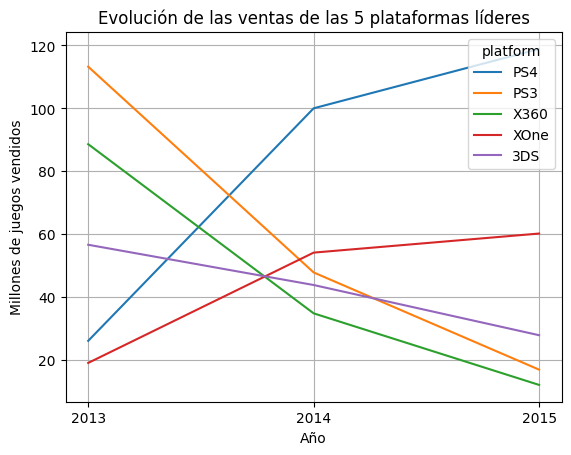

In [13]:
df_ventas = (
    df_relevante.groupby(
        ["platform", "year_of_release"]
    )["total_sales"]
    .sum()
)

grafica = df_ventas.unstack(level=0)


ax = grafica[top_5["platform"]].plot(title="Evolución de las ventas de las 5 plataformas líderes", 
                                     ylabel = "Millones de juegos vendidos", 
                                     xlabel = "Año",
                                    grid = True)
ax.set_xticks(grafica.index.astype("int64"))
plt.show()


Comparación de ventas entre las principales plataformas

En esta sección se analizará la distribución de las ventas totales de las principales plataformas identificadas en el período de estudio. El objetivo es comparar no solo el rendimiento promedio de cada plataforma, sino también la dispersión y variabilidad de sus ventas, con el fin de entender mejor cómo se comporta el mercado en términos de éxito comercial por título.

Para ello, se filtrarán únicamente las cinco plataformas con mayores ventas y se construirá un diagrama de cajas (boxplot) que permita visualizar la distribución de total_sales en cada una de ellas. Este tipo de gráfico es útil para identificar diferencias en la mediana de ventas, la presencia de valores atípicos y la concentración de los datos.

Adicionalmente, se utilizará una escala logarítmica en el eje de ventas para facilitar la visualización de diferencias amplias entre juegos con ventas muy altas y juegos con ventas más moderadas. Esto permitirá una comparación más clara entre plataformas y una mejor interpretación de la variabilidad del mercado.

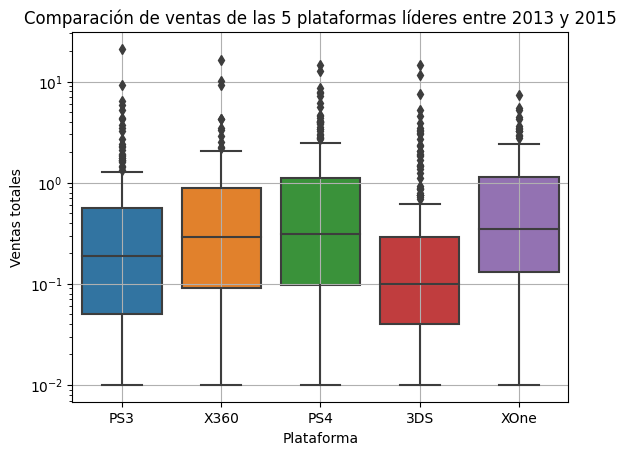

In [14]:
df_boxplot = df_relevante[df_relevante["platform"].isin(top_5["platform"])]
ax = sns.boxplot(data=df_boxplot, 
            x=df_boxplot["platform"], 
            y=df_boxplot["total_sales"]
)
ax.grid(True)
plt.title("Comparación de ventas de las 5 plataformas líderes entre 2013 y 2015")
plt.xlabel("Plataforma")
plt.ylabel("Ventas totales")
ax.set_yscale("log")
plt.show()

Las plataformas PS4 y XOne presentan las medianas de ventas más altas, lo que indica que un juego típico tiende a vender más en estas plataformas. Además, muestran una mayor dispersión en las ventas, reflejando una diferencia importante entre los juegos más exitosos y los menos vendidos. Por su parte, PS3 y X360 presentan medianas ligeramente inferiores, aunque mantienen una dispersión considerable y numerosos valores atípicos, lo que indica la presencia de algunos títulos muy exitosos. La 3DS muestra la mediana más baja y una menor dispersión en comparación con las demás plataformas. En general, todas las plataformas presentan una gran cantidad de valores atípicos, lo que sugiere que la mayoría de los juegos tiene ventas relativamente bajas, mientras que unos pocos títulos concentran una parte importante de las ventas totales.

Relación entre reseñas y ventas en PS4

En esta sección se analizará la relación entre las reseñas de críticos y el desempeño en ventas de los videojuegos, utilizando como caso de estudio la plataforma PS4, ya que es una de las más representativas dentro del período analizado.

Para ello, se filtrará el conjunto de datos para trabajar únicamente con juegos de PS4 y se seleccionarán aquellos registros que cuentan con información válida en la variable critic_score. Esto permite asegurar que el análisis se realice únicamente con datos completos en ambas variables.

Posteriormente, se construirá un gráfico de dispersión que permitirá observar la relación entre las puntuaciones otorgadas por críticos y las ventas totales de los videojuegos. Este tipo de visualización es adecuado para identificar posibles patrones, tendencias o correlaciones entre ambas variables, y evaluar si una mayor calificación profesional se asocia con mayores niveles de ventas.

In [15]:
df_relevante.groupby("platform")[["critic_score", "user_score"]].count()

,critic_score,user_score
platform,,
3DS,61,68
DS,0,1
PC,104,110
PS3,121,177
PS4,154,156
PSP,1,2
PSV,67,86
Wii,0,7
WiiU,61,71


In [16]:
df_ps4 = df_relevante[df_relevante["platform"] == "PS4"]
df_ps4_critic_score = df_ps4.dropna(subset=["critic_score"])

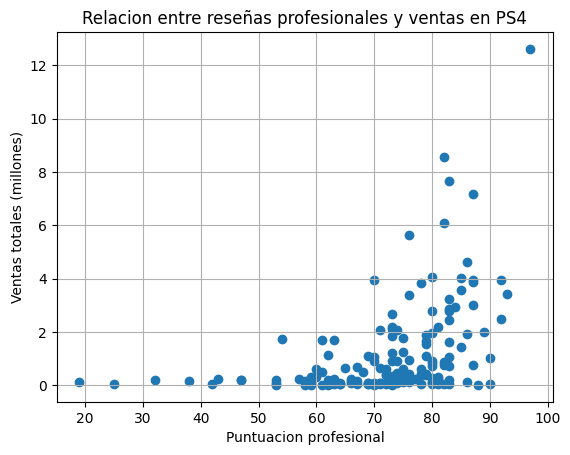

In [17]:
plt.scatter(x=df_ps4_critic_score["critic_score"], y=df_ps4_critic_score["total_sales"])
plt.title("Relacion entre reseñas profesionales y ventas en PS4")
plt.ylabel("Ventas totales (millones)")
plt.xlabel("Puntuacion profesional")
plt.grid(True)
plt.show()

Se observa una relación positiva entre las puntuaciones de los críticos y las ventas de los juegos de PS4. En general, los juegos con mejores reseñas tienden a alcanzar mayores ventas. Sin embargo, la dispersión de los puntos indica que la relación no es perfecta, ya que juegos con puntuaciones similares pueden presentar niveles de ventas muy diferentes. Además, se observan algunos valores atípicos correspondientes a títulos con ventas excepcionalmente altas.

In [18]:
df_ps4_user_score = df_ps4.dropna(subset=["user_score"])

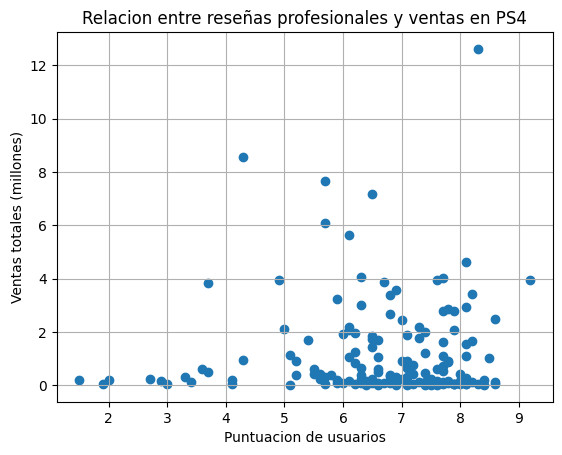

In [19]:
plt.scatter(x=df_ps4_user_score["user_score"], y=df_ps4_user_score["total_sales"])
plt.title("Relacion entre reseñas profesionales y ventas en PS4")
plt.ylabel("Ventas totales (millones)")
plt.xlabel("Puntuacion de usuarios")
plt.grid(True)
plt.show()

In [20]:
df_ps4_float_critic = df_ps4["critic_score"].astype(float)
df_ps4_correlacion_critic = df_ps4_float_critic.corr(df_ps4['total_sales'])
df_ps4_float_user = df_ps4["user_score"].astype(float)
df_ps4_correlacion_user = df_ps4_float_user.corr(df_ps4['total_sales'])

print(f"La correlación de reseñas de profesionales es {df_ps4_correlacion_critic:.2f}")
print(f"La correlación de reseñas de usuarios es {df_ps4_correlacion_user:.2f}")

La correlación de reseñas de profesionales es 0.43
La correlación de reseñas de usuarios es 0.02


Se observa una relación positiva entre las puntuaciones y las ventas de los juegos de PS4, aunque esta relación no es consistente entre los distintos tipos de reseñas y debe interpretarse con cautela debido a la limitada cantidad de datos disponibles. Las correlaciones calculadas se basan únicamente en una muestra reducida del total de juegos: 154 registros no nulos para las reseñas profesionales y 156 para las reseñas de usuarios, ya que la mayoría de los títulos no cuenta con calificaciones registradas.

Dentro de esta muestra, las reseñas profesionales muestran una correlación moderada con las ventas (0.43), lo que sugiere cierta relación entre la valoración de críticos y el desempeño comercial. En contraste, las reseñas de usuarios presentan una correlación prácticamente nula (0.02), lo que indica que no existe una relación significativa entre estas valoraciones y las ventas dentro del conjunto analizado.

Sin embargo, debido a la alta proporción de valores nulos y al tamaño reducido de la muestra utilizada para el cálculo, estos resultados no necesariamente representan el comportamiento real del total de juegos de PS4. Además, se mantiene una dispersión considerable en los datos y la presencia de valores atípicos, lo que refuerza la idea de que las puntuaciones, por sí solas, no explican completamente las diferencias en ventas.

Comparación de ventas de juegos entre plataformas

En esta sección se analizarán las diferencias en ventas de los mismos videojuegos entre distintas plataformas, con el objetivo de evaluar si un título mantiene un rendimiento similar o si su desempeño varía dependiendo del sistema en el que se lanza.

Para ello, se filtrarán los juegos disponibles en PS4 y se identificarán aquellos que también aparecen en las principales plataformas del período de estudio. A partir de este subconjunto, se agruparán las ventas por nombre de juego y plataforma para obtener el total de ventas de cada título en cada sistema.

Posteriormente, se construirá una tabla pivote que permitirá visualizar de forma comparativa las ventas de los mismos juegos entre las cinco plataformas más importantes. Esto facilitará la identificación de patrones de comportamiento, como diferencias significativas en el rendimiento de un mismo juego según la plataforma en la que se publique.

In [21]:
df_relevante.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
16,Grand Theft Auto V,PS3,2013,Action,7.02,9.09,0.98,3.96,97,8.2,M,21.05
23,Grand Theft Auto V,X360,2013,Action,9.66,5.14,0.06,1.41,97,8.1,M,16.27
31,Call of Duty: Black Ops 3,PS4,2015,Shooter,6.03,5.86,0.36,2.38,<NA>,NaN,NaN,14.63
33,Pokemon X/Pokemon Y,3DS,2013,Role-Playing,5.28,4.19,4.35,0.78,<NA>,NaN,NaN,14.60
42,Grand Theft Auto V,PS4,2014,Action,3.96,6.31,0.38,1.97,97,8.3,M,12.62


In [22]:
df_filtrado_ps4 = df_relevante[df_relevante["name"].isin(df_ps4["name"])]
df_filtrado_ps4.groupby(["name", "platform"])["total_sales"].sum()

name                                        platform
Adventure Time: Finn & Jake Investigations  3DS         0.09
                                            PS3         0.08
                                            PS4         0.10
                                            WiiU        0.05
                                            X360        0.09
                                                        ... 
Yoru no Nai Kuni                            PS4         0.08
                                            PSV         0.08
Zombie Army Trilogy                         PS4         0.20
                                            XOne        0.11
inFAMOUS: Second Son                        PS4         2.79
Name: total_sales, Length: 755, dtype: float64

In [23]:
df_top_5 = df_filtrado_ps4[df_filtrado_ps4["platform"].isin(top_5["platform"])]
df_top_5 = df_top_5.pivot_table(index="name",
                        columns="platform",
                        values="total_sales")
df_top_5.sort_values("PS4", ascending=False).head(10)

platform,3DS,PS3,PS4,X360,XOne
name,,,,,
Call of Duty: Black Ops 3,NaN,1.69,14.63,1.70,7.39
Grand Theft Auto V,NaN,21.05,12.62,16.27,5.47
FIFA 16,NaN,2.70,8.58,1.57,3.25
Star Wars Battlefront (2015),NaN,NaN,7.98,NaN,3.66
Call of Duty: Advanced Warfare,NaN,4.36,7.66,4.28,5.26
Fallout 4,NaN,NaN,7.17,NaN,4.22
FIFA 15,0.46,4.28,6.08,2.92,2.18
Destiny,NaN,1.61,5.64,1.92,3.37
The Last of Us,NaN,5.86,4.72,NaN,NaN


Aquí comparo las ventas de un mismo juego en las cinco plataformas líderes. En este caso, los valores nulos son totalmente normales, ya que indican que el juego no fue lanzado para esa plataforma. Al analizar los datos, se observa que varios de los títulos más vendidos alcanzan sus mayores ventas en PS4 o PS3. Por ejemplo, Call of Duty: Black Ops 3 vendió 14.63 millones de copias en PS4, muy por encima de las demás plataformas, mientras que Grand Theft Auto V obtuvo sus mejores resultados en PS3 y X360. Además, juegos como Fallout 4, Star Wars Battlefront y Uncharted: The Nathan Drake Collection muestran ventas importantes en PS4 y una presencia limitada o inexistente en otras plataformas. En general, los títulos exitosos suelen mantener buenas ventas en varias plataformas, aunque normalmente existe una plataforma dominante donde concentran la mayor parte de sus ventas. Esto respalda la idea de que PS4 fue una de las plataformas más fuertes del período analizado y una de las opciones más atractivas para lanzar nuevos títulos.

### Análisis de distribución de géneros

En esta sección se analizará la distribución de las ventas de videojuegos según su género, con el objetivo de identificar cuáles son los géneros más rentables dentro del período de estudio y cuáles presentan un menor desempeño en el mercado.

Para ello, se agruparán los datos por género y se calcularán las ventas totales, lo que permitirá observar qué tipos de videojuegos concentran la mayor parte de los ingresos. Este análisis ayudará a comprender las preferencias generales de los consumidores y a detectar posibles patrones de consumo en la industria.

Los resultados obtenidos servirán como base para complementar el análisis por plataformas y regiones, ya que el género es una de las variables clave en la definición del éxito comercial de un videojuego.


<AxesSubplot:title={'center':'Ventas por cada género 2013-2015'}, xlabel='Géneros', ylabel='Ventas (millones)'>

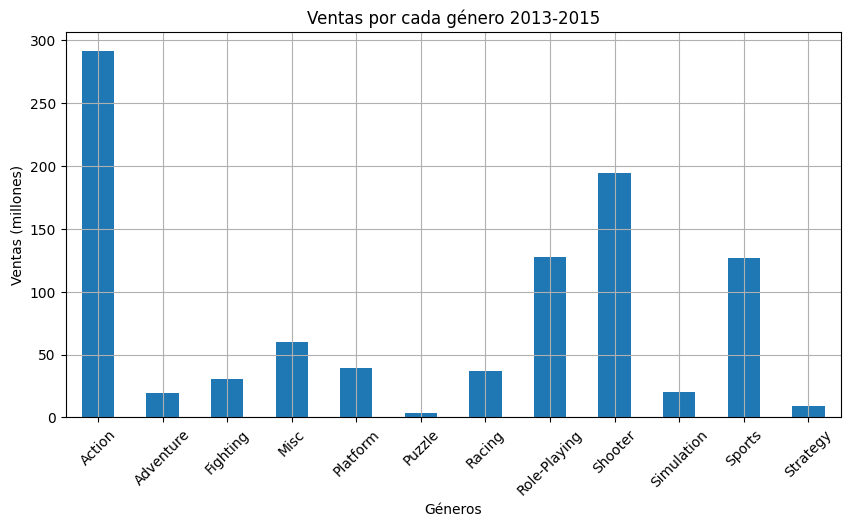

In [24]:
df_generos = df_relevante.groupby("genre")["total_sales"].sum()
df_generos.plot(kind="bar",
                title="Ventas por cada género 2013-2015",
                rot=45,
                ylabel="Ventas (millones)",
                xlabel="Géneros",
                figsize=(10, 5),
                grid=True
               )

Entre 2013 y 2015 se observa que el mercado de los videojuegos estuvo claramente dominado por el género de Acción, que fue el que más ventas acumuló, acercándose a los 300 millones y destacándose por encima del resto. Antes de interpretar estas diferencias, es importante tener en cuenta que los resultados pueden estar influenciados por la cantidad de títulos lanzados por género, ya que categorías con más juegos publicados tienden a acumular mayores ventas totales.

En segundo lugar se encuentran los Shooters, con cifras también muy altas, rondando los 200 millones, lo que refuerza la importancia de estos géneros dentro del mercado en ese periodo. Los géneros de Rol y Deportes presentan un rendimiento intermedio, manteniendo buenas ventas pero sin llegar a competir con los líderes. En contraste, los géneros de Estrategia y Puzzle fueron los menos vendidos durante este periodo, quedando bastante por debajo del resto.

En general, los datos entre 2013 y 2015 muestran una tendencia hacia mayores ventas en juegos de acción y disparos, aunque estas diferencias no necesariamente reflejan una preferencia directa del consumidor, sino que también pueden estar condicionadas por la cantidad de lanzamientos en cada género.

### Análisis del perfil de usuario por región

En esta sección se analizarán las diferencias en el comportamiento de los usuarios entre las regiones de Norteamérica (NA), Europa (EU) y Japón (JP), con el objetivo de identificar posibles variaciones en sus preferencias de consumo.

Para ello, se calcularán las cinco plataformas, géneros y clasificaciones ESRB con mayores ventas en cada región. Este análisis permitirá comparar cómo cambia la popularidad de cada categoría dependiendo del mercado, evidenciando posibles diferencias culturales o de consumo entre regiones.

Los resultados obtenidos servirán como base para construir el perfil de usuario de cada región, lo cual es fundamental para entender qué tipo de videojuegos tienen mayor éxito en cada mercado y apoyar la toma de decisiones en estrategias de lanzamiento y marketing.


In [25]:

df_na_platforms = (
    df_relevante.groupby("platform")["na_sales"]
    .sum()
    .sort_values(ascending=False)
    .head(5)

)
df_na_genre = (
    df_relevante.groupby("genre")["na_sales"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)
df_na_rating = (
    df_relevante.groupby("rating")["na_sales"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)
df_eu_platforms = (
    df_relevante.groupby("platform")["eu_sales"]
    .sum()
    .sort_values(ascending=False)
    .head(5)

)
df_eu_genre = (
    df_relevante.groupby("genre")["eu_sales"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)
df_eu_rating = (
    df_relevante.groupby("rating")["eu_sales"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)
df_jp_platforms = (
    df_relevante.groupby("platform")["jp_sales"]
    .sum()
    .sort_values(ascending=False)
    .head(5)

)
df_jp_genre = (
    df_relevante.groupby("genre")["jp_sales"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)
df_jp_rating = (
    df_relevante.groupby("rating")["jp_sales"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

In [26]:
print("TOP 5 PLATAFORMAS - NA")
print(df_na_platforms)
print("\n")

print("TOP 5 PLATAFORMAS - EU")
print(df_eu_platforms)
print("\n")

print("TOP 5 PLATAFORMAS - JP")
print(df_jp_platforms)
print("\n")

TOP 5 PLATAFORMAS - NA
platform
PS4     87.25
X360    80.97
XOne    78.85
PS3     62.83
3DS     34.06
Name: na_sales, dtype: float64


TOP 5 PLATAFORMAS - EU
platform
PS4     109.31
PS3      66.55
XOne     41.96
X360     41.81
3DS      28.63
Name: eu_sales, dtype: float64


TOP 5 PLATAFORMAS - JP
platform
3DS     59.78
PS3     22.05
PSV     15.03
PS4     10.22
WiiU    10.21
Name: jp_sales, dtype: float64




In [27]:
print("TOP 5 GÉNEROS - NA")
print(df_na_genre)
print("\n")

print("TOP 5 GÉNEROS - EU")
print(df_eu_genre)
print("\n")

print("TOP 5 GÉNEROS - JP")
print(df_jp_genre)
print("\n")

TOP 5 GÉNEROS - NA
genre
Action          116.76
Shooter          93.50
Sports           57.73
Role-Playing     40.51
Misc             26.73
Name: na_sales, dtype: float64


TOP 5 GÉNEROS - EU
genre
Action          107.45
Shooter          71.96
Sports           48.51
Role-Playing     32.69
Misc             19.38
Name: eu_sales, dtype: float64


TOP 5 GÉNEROS - JP
genre
Role-Playing    44.43
Action          33.42
Misc             8.16
Fighting         6.90
Shooter          5.55
Name: jp_sales, dtype: float64




In [28]:
print("TOP 5 RATINGS - NA")
print(df_na_rating)
print("\n")

print("TOP 5 RATINGS - EU")
print(df_eu_rating)
print("\n")

print("TOP 5 RATINGS - JP")
print(df_jp_rating)
print("\n")

TOP 5 RATINGS - NA
rating
M       149.54
E        71.08
E10+     50.43
T        40.84
Name: na_sales, dtype: float64


TOP 5 RATINGS - EU
rating
M       128.78
E        69.75
E10+     38.88
T        32.16
Name: eu_sales, dtype: float64


TOP 5 RATINGS - JP
rating
T       18.32
E       14.07
M       12.91
E10+     5.44
Name: jp_sales, dtype: float64




Entre las regiones de NA, EU y JP se observan diferencias claras en las preferencias de plataformas, géneros y clasificaciones ESRB, lo que demuestra que el mercado de videojuegos no se comporta de manera uniforme a nivel global.

En NA y EU el comportamiento es muy similar: las plataformas más populares son PS4 y consolas de la familia Xbox, los géneros más vendidos son Action, Shooter y Sports, y predominan los juegos con clasificación M. Esto sugiere un mercado bastante alineado entre ambas regiones, con preferencias orientadas a experiencias de acción, competitivas y con contenido más maduro, por lo que una estrategia de ventas o marketing podría ser prácticamente compartida entre estos dos mercados.

En cambio, Japón presenta un patrón distinto. La plataforma más fuerte es la 3DS, seguida de otras consolas portátiles, y el género dominante es Role-Playing (RPG), lo que indica una mayor preferencia por juegos narrativos y de progresión. Además, el rating más vendido es T, lo que refuerza un perfil de consumidor diferente al occidental.

En conclusión, aunque NA y EU permiten estrategias bastante similares debido a sus patrones de consumo parecidos, Japón requiere un enfoque completamente distinto y adaptado a su mercado. Esto implica que una empresa no debería reutilizar la misma estrategia global, sino ajustar sus decisiones de plataformas, géneros y tipo de contenido según cada región para maximizar su impacto en ventas.


### Prueba de hipótesis: comparación de calificaciones entre plataformas

En esta sección se evaluará si existen diferencias significativas en las calificaciones promedio de los usuarios entre las plataformas XOne y PC, con el objetivo de determinar si la percepción del usuario varía según la plataforma de juego.

Para ello, se realizará una prueba estadística t para dos muestras independientes, la cual permite comparar las medias de `user_score` entre ambos grupos. Antes de aplicar la prueba, se eliminarán los valores ausentes en la variable de calificación para asegurar la validez del análisis.

El resultado de esta prueba será evaluado utilizando un nivel de significancia de α = 0.05. Esto permitirá determinar si las posibles diferencias observadas entre ambas plataformas son estadísticamente significativas o si pueden atribuirse al azar.


In [29]:
df_calificacion_usuarios_xone = df_relevante[df_relevante["platform"] == "XOne"]
df_calificacion_usuarios_pc = df_relevante[df_relevante["platform"] == "PC"]
xone = df_calificacion_usuarios_xone["user_score"]
pc = df_calificacion_usuarios_pc["user_score"]
xone = xone.dropna()
pc = pc.dropna()
resultado = stats.ttest_ind(xone, pc, equal_var=False)

alpha = 0.05

if resultado.pvalue < alpha:
    print(f"""
p-value = {resultado.pvalue:.4f}

Se rechaza la hipótesis nula.
Hay diferencias significativas entre las medias de user_score en XOne y PC.
""")
else:
    print(f"""
p-value = {resultado.pvalue:.4f}

No se puede rechazar la hipótesis nula.
No hay evidencia suficiente de diferencias significativas entre las medias de user_score en XOne y PC.
""")


p-value = 0.2867

No se puede rechazar la hipótesis nula.
No hay evidencia suficiente de diferencias significativas entre las medias de user_score en XOne y PC.



Se realizó una prueba t para dos muestras independientes con el objetivo de comparar las medias de las calificaciones de usuarios (user_score) entre las plataformas XOne y PC.

La hipótesis nula (H₀) plantea que no existen diferencias significativas entre las medias de user_score de XOne y PC. La hipótesis alternativa (H₁) establece que sí existen diferencias significativas entre las medias de ambas plataformas.

Para evaluar estas hipótesis se utilizó una prueba t de Student para muestras independientes, con un nivel de significancia de α = 0.05. Este criterio implica que si el p-value es menor a 0.05, se rechaza la hipótesis nula; de lo contrario, no se rechaza. En este caso, el p-value obtenido fue de 0.2867, por lo que no se rechaza H₀.

Desde un punto de vista práctico, este resultado sugiere que no hay diferencias estadísticamente significativas en las calificaciones promedio de los usuarios entre XOne y PC. Para una empresa, esto implica que la satisfacción del usuario no parece depender de manera relevante de la plataforma en este caso específico, por lo que la decisión de enfocarse en una u otra debería basarse en otros factores como ventas, tamaño del mercado o costos de desarrollo, más que en diferencias en percepción de los usuarios.

### Prueba de hipótesis: comparación de calificaciones entre géneros (Action vs Sports)

En esta sección se evaluará si existen diferencias significativas en las calificaciones promedio de los usuarios entre los géneros Action y Sports, con el objetivo de analizar si el tipo de género influye en la percepción de los jugadores.

Para ello, se realizará una prueba t para dos muestras independientes, la cual permite comparar las medias de `user_score` entre ambos grupos. Antes de aplicar la prueba, se filtrarán los datos para seleccionar únicamente los juegos correspondientes a cada género y se eliminarán los valores ausentes en la variable de calificación, asegurando así la validez del análisis estadístico.

El resultado de la prueba será interpretado utilizando un nivel de significancia de α = 0.05, lo que permitirá determinar si las diferencias observadas entre ambos géneros son estadísticamente significativas o si pueden atribuirse al azar.


In [30]:
df_accion = df_relevante[df_relevante["genre"] == "Action"]
df_deportes = df_relevante[df_relevante["genre"] == "Sports"]
accion = df_accion["user_score"]
deportes = df_deportes["user_score"]
accion = accion.dropna()
deportes = deportes.dropna()
resultado2 = stats.ttest_ind(accion, deportes, equal_var=False)

alpha = 0.05

if resultado2.pvalue < alpha:
    print(f"""
p-value = {resultado2.pvalue:.4f}

Se rechaza la hipótesis nula.
Existen diferencias significativas entre las medias de user_score de Action y Sports.
""")
else:
    print(f"""
p-value = {resultado2.pvalue:.4f}

No se rechaza la hipótesis nula.
No hay evidencia suficiente de diferencias significativas entre las medias de user_score de Action y Sports.
""")


p-value = 0.0000

Se rechaza la hipótesis nula.
Existen diferencias significativas entre las medias de user_score de Action y Sports.



En este análisis se estudió el comportamiento del mercado de videojuegos a partir de ventas, puntuaciones de usuarios y críticos, plataformas, géneros y regiones, combinando análisis descriptivo y pruebas estadísticas.

En cuanto a las correlaciones, se observó que en la plataforma PS4 existe una relación positiva moderada entre las reseñas de críticos y las ventas (0.43), mientras que las reseñas de usuarios presentan una correlación prácticamente nula (0.02). Esto indica que, en este caso específico, las evaluaciones profesionales están más relacionadas con el desempeño comercial que las opiniones de los usuarios, aunque estos resultados deben interpretarse considerando que se basan en una muestra reducida de datos debido a valores nulos.

A nivel regional, se identifican diferencias claras en el comportamiento del mercado. NA y EU presentan patrones muy similares, con predominancia de plataformas como PS4 y Xbox, géneros como Action, Shooter y Sports, y una mayor presencia de juegos con clasificación M. En contraste, Japón muestra un perfil distinto, donde destaca la consola 3DS, el género Role-Playing (RPG) y una mayor presencia de clasificaciones T, lo que evidencia diferencias culturales en las preferencias de consumo.

En las pruebas estadísticas, se encontró que no existen diferencias significativas en las calificaciones de usuarios entre XOne y PC (p-value = 0.2867), lo que sugiere que la percepción del usuario es similar entre estas dos plataformas. Sin embargo, sí se encontraron diferencias significativas entre los géneros Action y Sports (p-value ≈ 3.5e-19), aunque este resultado debe interpretarse con cautela, ya que en muestras grandes incluso diferencias pequeñas pueden generar p-values extremadamente bajos.

En conjunto, los resultados muestran que el mercado de videojuegos es altamente dependiente de la región y del tipo de juego. Mientras que comparaciones como XOne vs PC no muestran diferencias en la percepción del usuario, otras como los géneros sí presentan variaciones significativas en las valoraciones.

🔎 Conclusión final y recomendación

A partir de los hallazgos, la recomendación más importante para una empresa es adaptar completamente su estrategia según la región. Para el mercado norteamericano y europeo, donde los patrones son similares, sería viable lanzar juegos enfocados en acción, shooters y deportes en consolas como PS4 y Xbox, ya que existe un comportamiento de consumo bastante homogéneo. En cambio, para Japón, la estrategia debe ser completamente distinta, priorizando juegos tipo RPG, experiencias narrativas y plataformas portátiles como la 3DS, ya que el perfil del consumidor es estructuralmente diferente.